In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns
import pylab as pl
import pandas as pd
import numpy as np
import scipy as sp
from scipy import stats
from scipy.stats import invgauss
from sklearn.model_selection import KFold
from typing import NamedTuple
import yaml
import shelve

from caa_model.config import *
from caa_model.utils.get_yaml_data import ERStruct, RTConf, reformat_revised_data
from caa_model.models.base_model import BaseDDM
from caa_model.config import EPS
from caa_model.utils.multinomial_funcs import multinom_loglike

## Setup

In [2]:
caa_cfg = CAAConfig(
    delta_t=0.025,
    nr_ssteps=8192,
    nr_samples=10000,
    max_t=10.0,
)

db = shelve.open("data/neha_data_revised.yml.dat", "r")
data_group = db["empirical_results"]
db.close()

db = shelve.open("data/mengxue_data.yml.dat", "r")
data_subject = db["empirical_results"]
db.close()

def get_subject_data(full_data, subject_id):
    subject_id = str(subject_id).strip()

    # Order must match ERStruct: ["know_hit", "rem_hit", "know_fa", "rem_fa", "CR", "miss"]
    categories = ["know_hit", "rem_hit", "know_fa", "rem_fa", "CR", "miss"]
    filtered_cats = []

    for category in categories:
        cat_data = getattr(full_data, category)
        mask = cat_data.subj == subject_id

        filtered_cat = RTConf(
            rt=cat_data.rt[mask],
            conf=cat_data.conf[mask],
            target=cat_data.target[mask],
            subj=cat_data.subj[mask],
        )
        filtered_cats.append(filtered_cat)

    # Returning top-level ERStruct makes it fully picklable for parallel workers
    return ERStruct(*filtered_cats)

# Dynamically grab unique subjects
subject_ids = np.unique(data_subject.rem_hit.subj)
print(f"Found {len(subject_ids)} subjects to fit.")

Found 4 subjects to fit.


## RT Aggregated

### Setup

In [4]:
# --- 3. SATURATED NLL FLOOR LOGIC ---
def get_saturated_qmpe_nll(rts_old, rts_new):
    n_old = len(rts_old)
    n_new = len(rts_new)
    N = n_old + n_new
    if N == 0:
        return 0.0

    props = np.array([0.1, 0.2, 0.2, 0.2, 0.2, 0.1])
    x_old = n_old * props
    x_new = n_new * props
    x = np.concatenate([x_old, x_new])

    p = x / N
    return -multinom_loglike(x, N, p)

### Wiener Two Bound


 INITIALIZING ANALYSIS FOR AGGREGATED GROUP
Fitting 8-Parameter Boundary Physics...
differential_evolution step 1: f(x)= 2152.3732345779663
differential_evolution step 2: f(x)= 2152.3732345779663
differential_evolution step 3: f(x)= 2152.3732345779663
differential_evolution step 4: f(x)= 2152.3732345779663
differential_evolution step 5: f(x)= 2152.3732345779663
differential_evolution step 6: f(x)= 1379.9711278999075
differential_evolution step 7: f(x)= 1379.9711278999075
differential_evolution step 8: f(x)= 1379.9711278999075
differential_evolution step 9: f(x)= 1379.9711278999075
differential_evolution step 10: f(x)= 1328.6069831970399
differential_evolution step 11: f(x)= 1243.1186218640178
differential_evolution step 12: f(x)= 1088.2521579664826
differential_evolution step 13: f(x)= 845.9841439790871
differential_evolution step 14: f(x)= 845.9841439790871
differential_evolution step 15: f(x)= 717.1220620637323
differential_evolution step 16: f(x)= 304.4737251981369
differential_evo

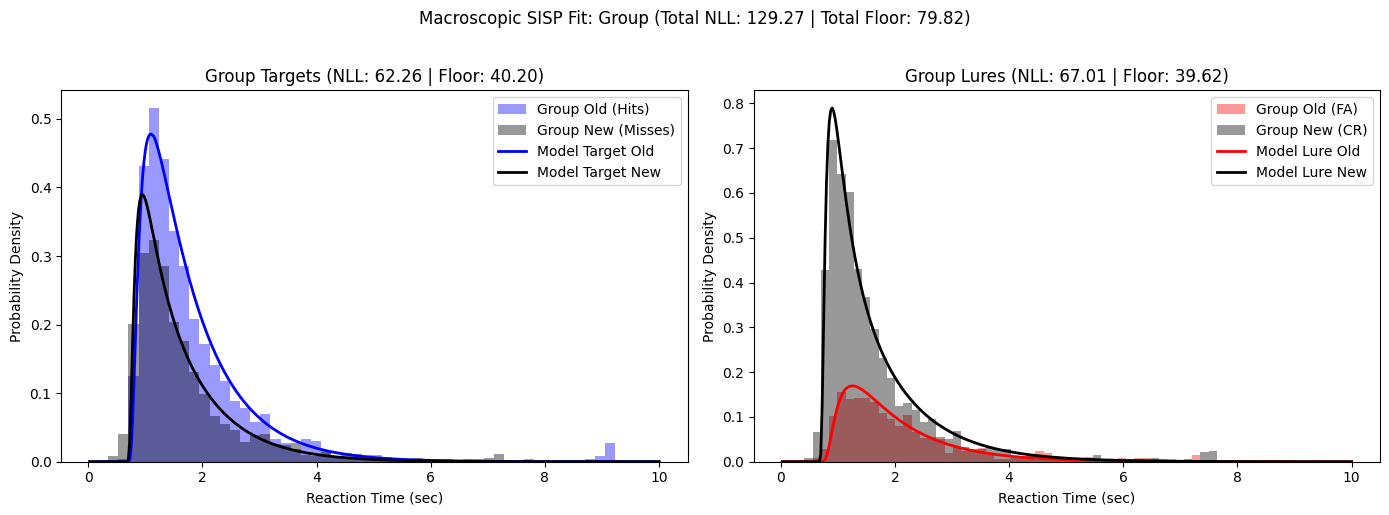

In [7]:
# --- 4. MACROSCOPIC SISP MODEL ---
class MacroscopicSISP(BaseDDM):
    """2-Choice Macroscopic limit test for a specific subject."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        d_t: float
        d_l: float
        tc_bound: float
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        return (mu_t, d_t, tc, z0_t, t0, True), (mu_l, d_l, tc, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_r, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            p_pos = tx[i][x >= bound[i]]
            p_old[i] = pl.sum(p_pos)
            p_new[i] = pl.sum(tx[i][x <= -bound[i]])
            tx[i] *= abs(x) < bound[i]

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0:
            return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0:
            return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- 5. EXECUTION WRAPPER ---
# --- 5. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    """Core fitting and plotting logic, abstracted to handle both Subjects and Group data."""
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = MacroscopicSISP(config=config)

    # Constrain z0 within valid boundaries (-0.8 to 0.8)
    param_bounds = (
        MacroscopicSISP.Params(mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0),
        MacroscopicSISP.Params(mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=0.8, z0_l=0.8, t0=1.0),
    )

    print(f"Fitting 8-Parameter Boundary Physics...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting with shared bin edges
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts))
    t_max = max(np.max(t_old_rts), np.max(t_new_rts))
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
    w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)

    axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")
    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts))
    l_max = max(np.max(l_old_rts), np.max(l_new_rts))
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
    w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)

    axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")
    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic SISP Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_group(data_group)

# Params(mu_t=np.float64(0.32415813577552266), mu_l=np.float64(-0.2534523877165345), d_t=np.float64(0.5487854042162205), d_l=np.float64(0.4878021395134811), tc_bound=np.float64(0.0003135076686020443), z0_t=np.float64(-0.1161266810772989), z0_l=np.float64(-0.2519533133916583), t0=np.float64(0.6731714926374323))

### Variable Drift Rate


 INITIALIZING ANALYSIS FOR SUBJECT: 7
Fitting 10-Parameter Model (with Drift Variability)...
differential_evolution step 1: f(x)= 1331.3538265564816
differential_evolution step 2: f(x)= 735.8434503201138
differential_evolution step 3: f(x)= 735.8434503201138
differential_evolution step 4: f(x)= 531.6395456476862
differential_evolution step 5: f(x)= 531.6395456476862
differential_evolution step 6: f(x)= 498.3884376235296
differential_evolution step 7: f(x)= 498.3884376235296
differential_evolution step 8: f(x)= 385.9068332728011
differential_evolution step 9: f(x)= 385.9068332728011
differential_evolution step 10: f(x)= 385.9068332728011
differential_evolution step 11: f(x)= 385.9068332728011
differential_evolution step 12: f(x)= 355.89591908266084
differential_evolution step 13: f(x)= 239.65395820135018
differential_evolution step 14: f(x)= 239.65395820135018
differential_evolution step 15: f(x)= 211.61833882256678
differential_evolution step 16: f(x)= 208.5885479933138
differential_e

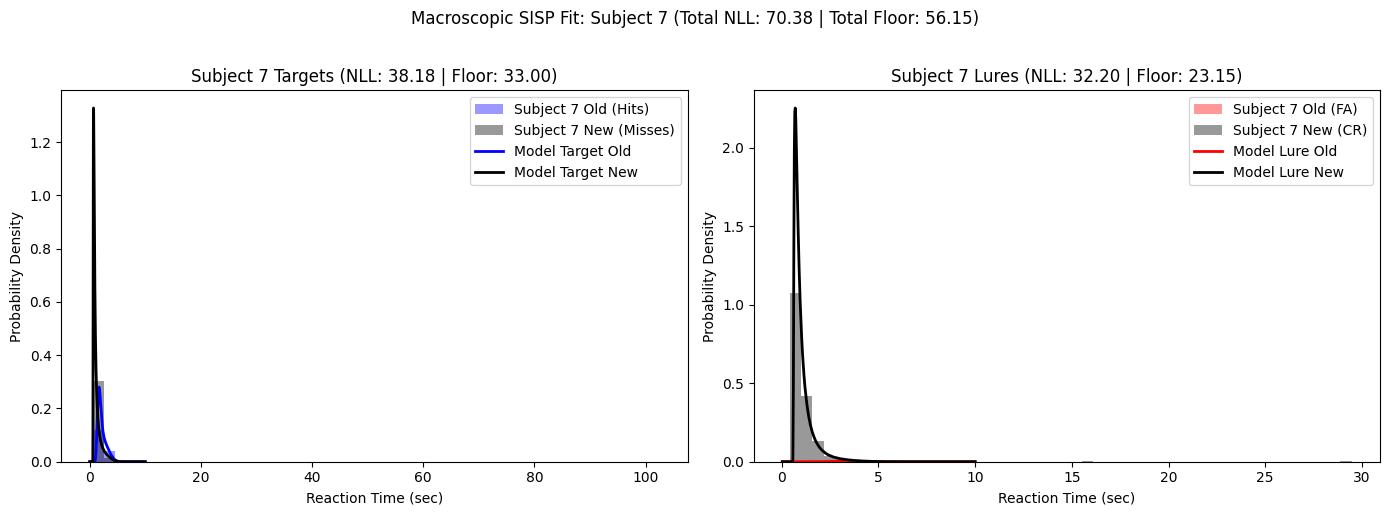

In [16]:
class DriftVariabilityMacroscopicSISP(BaseDDM):
    """2-Choice Macroscopic limit test with Intertrial Drift Variability (eta)."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        eta_t: float    # NEW: Target drift variability
        eta_l: float    # NEW: Lure drift variability
        d_t: float
        d_l: float
        tc_bound: float
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, eta_t, eta_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        return (mu_t, eta_t, d_t, tc, z0_t, t0, True), (mu_l, eta_l, d_l, tc, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_mean, eta, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        t = pl.linspace(delta_t, max_t, nr_tsteps)
        p_old_total = pl.zeros(pl.shape(t))
        p_new_total = pl.zeros(pl.shape(t))

        # 5-Node Gauss-Hermite Quadrature for standard normal distribution
        nodes = np.array([-2.85697001, -1.35562618,  0.0,  1.35562618,  2.85697001])
        weights = np.array([0.01125741,  0.22207592,  0.53333333,  0.22207592,  0.01125741])

        # If variance is virtually zero, skip the loop to save compute time
        if eta < 1e-4:
            drift_rates = [mu_mean]
            drift_weights = [1.0]
        else:
            drift_rates = mu_mean + (nodes * eta)
            drift_weights = weights

        sigma = pl.sqrt(2 * d * delta_t)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        # Evolve the probability cloud for each sample drift rate
        for mu_val, weight in zip(drift_rates, drift_weights):
            mu = mu_val * delta_t

            kernel = stats.norm.pdf(x, mu, sigma) * delta_s
            ft_kernel = self._fft(kernel)

            tx = pl.zeros((len(t), len(x)))
            p_old = pl.zeros(pl.shape(t))
            p_new = pl.zeros(pl.shape(t))

            tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

            for i in range(to_idx, len(t)):
                if i > to_idx:
                    tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

                p_pos = tx[i][x >= bound[i]]
                p_old[i] = pl.sum(p_pos)
                p_new[i] = pl.sum(tx[i][x <= -bound[i]])
                tx[i] *= abs(x) < bound[i]

            # Multiply by the quadrature weight and add to total
            p_old_total += p_old * weight
            p_new_total += p_new * weight

        return p_old_total, p_new_total, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0:
            return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0:
            return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- 5. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = DriftVariabilityMacroscopicSISP(config=config)

    # UPDATED: Added eta_t and eta_l to the param_bounds
    # (Allowing drift variability to stretch from 0.0 up to 2.0 standard deviations)
    param_bounds = (
        DriftVariabilityMacroscopicSISP.Params(mu_t=-2.0, mu_l=-2.0, eta_t=0.0, eta_l=0.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0),
        DriftVariabilityMacroscopicSISP.Params(mu_t=2.0, mu_l=2.0, eta_t=2.0, eta_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=0.8, z0_l=0.8, t0=1.0),
    )

    print(f"Fitting 10-Parameter Model (with Drift Variability)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting with shared bin edges
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts))
    t_max = max(np.max(t_old_rts), np.max(t_new_rts))
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
    w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)

    axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")
    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts))
    l_max = max(np.max(l_old_rts), np.max(l_new_rts))
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
    w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)

    axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")
    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic SISP Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_subject("7")

In [17]:
eval_result.params

Params(mu_t=np.float64(0.18499533640226695), mu_l=np.float64(-0.1920371795765213), eta_t=np.float64(0.6880021318044454), eta_l=np.float64(0.01884281984196741), d_t=np.float64(0.09195752664549996), d_l=np.float64(0.07157833525217774), tc_bound=np.float64(0.33221899193403537), z0_t=np.float64(-0.7266622635216042), z0_l=np.float64(-0.7929307332106162), t0=np.float64(0.5808254614432357))

### 

### Inv Gauss


 INITIALIZING ANALYSIS FOR AGGREGATED GROUP
Fitting Independent Inverse Gaussian Distributions...

--- RESULTS FOR Group ---
 Absolute NLL Floor:    79.82 (Target: 40.20, Lure: 39.62)
 Independent InvGauss:  200.42 (Target: 100.71, Lure: 99.71)
 Total NLL Penalty:     120.60


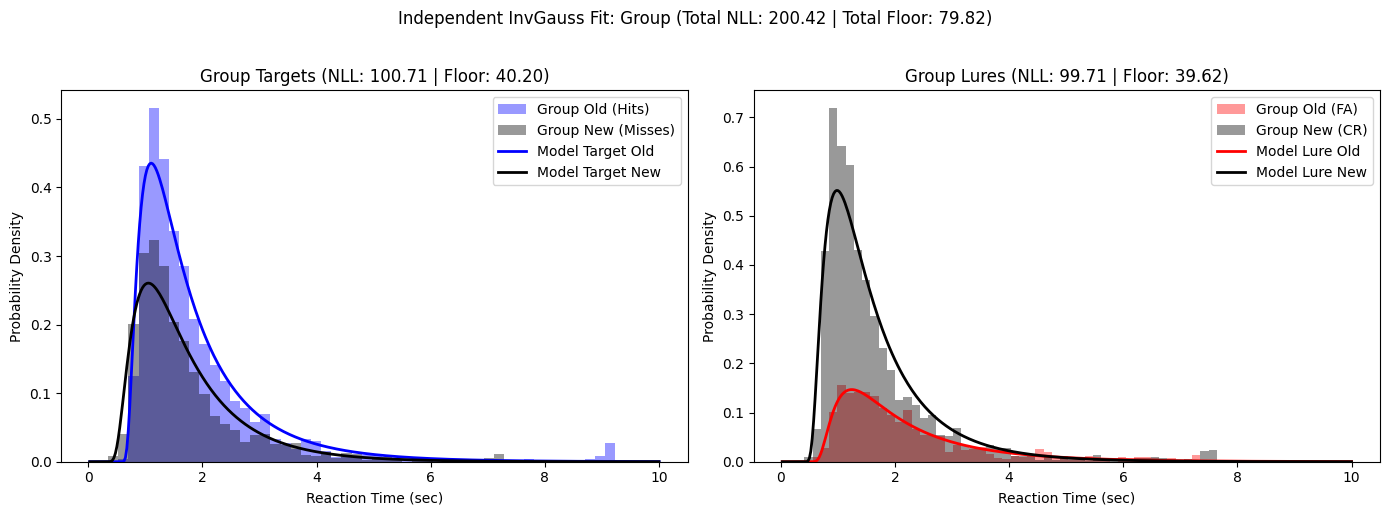

In [ ]:
# --- 4. INDEPENDENT INVERSE GAUSSIAN MODEL ---
class InvGaussMacroscopicSISP(BaseDDM):
    """
    Fits independent Inverse Gaussian distributions to each of the 4 response categories:
    Target Old (Hits), Target New (Misses), Lure Old (False Alarms), Lure New (Correct Rejections).
    """

    class Params(NamedTuple):
        # Target Old (Hits)
        mu_t_old: float
        scale_t_old: float
        t0_t_old: float
        # Target New (Misses)
        mu_t_new: float
        scale_t_new: float
        t0_t_new: float
        p_t_old: float       # Choice proportion for Old given Target

        # Lure Old (False Alarms)
        mu_l_old: float
        scale_l_old: float
        t0_l_old: float
        # Lure New (Correct Rejections)
        mu_l_new: float
        scale_l_new: float
        t0_l_new: float
        p_l_old: float       # Choice proportion for Old given Lure

    @staticmethod
    def split_params(model_params):
        """Splits the 14 parameters into target and lure subsets."""
        p = model_params
        target_params = (p.mu_t_old, p.scale_t_old, p.t0_t_old, p.mu_t_new, p.scale_t_new, p.t0_t_new, p.p_t_old)
        lure_params = (p.mu_l_old, p.scale_l_old, p.t0_l_old, p.mu_l_new, p.scale_l_new, p.t0_l_new, p.p_l_old)
        return target_params, lure_params

    def predicted_proportions(self, params):
        """
        Computes discrete predicted probability mass across time grid t
        for Old and New responses using the fitted Inverse Gaussian distributions.
        """
        mu_old, scale_old, t0_old, mu_new, scale_new, t0_new, p_old_choice = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        t = pl.linspace(delta_t, max_t, nr_tsteps)

        # Evaluate continuous Inverse Gaussian density
        pdf_old = invgauss.pdf(t, mu_old, loc=t0_old, scale=scale_old)
        pdf_new = invgauss.pdf(t, mu_new, loc=t0_new, scale=scale_new)

        # Normalize density over finite grid
        sum_old = pl.sum(pdf_old * delta_t)
        sum_new = pl.sum(pdf_new * delta_t)
        if sum_old > 0:
            pdf_old /= sum_old
        if sum_new > 0:
            pdf_new /= sum_new

        # Scale by choice probability mass
        p_old = p_old_choice * pdf_old * delta_t
        p_new = (1.0 - p_old_choice) * pdf_new * delta_t

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0:
            return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0:
            return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

    def _fit_single_distribution(self, rts):
        """Fits an Inverse Gaussian to a single 1D reaction time array."""
        if len(rts) == 0:
            return 1.0, 1.0, 0.2
        try:
            # Maximum-likelihood fit via scipy.stats
            shape, loc, scale = invgauss.fit(rts)
            # Guarantee shift (t0) is strictly prior to earliest RT
            min_rt = np.min(rts)
            if loc >= min_rt:
                loc = min_rt * 0.8
            return shape, scale, loc
        except Exception:
            return 1.0, float(np.std(rts)), float(np.min(rts) * 0.8)

    def fit(self, param_bounds=None, data=None, nr_workers=1, method="qmpe", use_chisq=False):
        """
        Fits each of the 4 distributions independently directly to the empirical RTs,
        bypassing the slow 14D joint search while guaranteeing decoupled parameter recovery.
        """
        t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
        t_new_rts = data.miss.rt
        l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
        l_new_rts = data.CR.rt

        # Compute empirical choice proportions
        n_t_old = len(t_old_rts)
        n_t_new = len(t_new_rts)
        n_l_old = len(l_old_rts)
        n_l_new = len(l_new_rts)

        p_t_old = n_t_old / (n_t_old + n_t_new) if (n_t_old + n_t_new) > 0 else 0.5
        p_l_old = n_l_old / (n_l_old + n_l_new) if (n_l_old + n_l_new) > 0 else 0.5

        # Fit each distribution independently
        mu_t_old, scale_t_old, t0_t_old = self._fit_single_distribution(t_old_rts)
        mu_t_new, scale_t_new, t0_t_new = self._fit_single_distribution(t_new_rts)
        mu_l_old, scale_l_old, t0_l_old = self._fit_single_distribution(l_old_rts)
        mu_l_new, scale_l_new, t0_l_new = self._fit_single_distribution(l_new_rts)

        return self.Params(
            mu_t_old=mu_t_old, scale_t_old=scale_t_old, t0_t_old=t0_t_old,
            mu_t_new=mu_t_new, scale_t_new=scale_t_new, t0_t_new=t0_t_new,
            p_t_old=p_t_old,
            mu_l_old=mu_l_old, scale_l_old=scale_l_old, t0_l_old=t0_l_old,
            mu_l_new=mu_l_new, scale_l_new=scale_l_new, t0_l_new=t0_l_new,
            p_l_old=p_l_old
        )

# --- 5. EXECUTION WRAPPER ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_invgauss_analysis("Subject " + subject_id, subj_data, config)


def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_invgauss_analysis("Group", group_data, config)


def _run_invgauss_analysis(label, dataset, config):
    """Core fitting and plotting logic for Inverse Gaussian model."""
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = InvGaussMacroscopicSISP(config=config)

    print(f"Fitting Independent Inverse Gaussian Distributions...")
    best_params = model.fit(data=dataset, method="qmpe")
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:    {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Independent InvGauss:  {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:     {eval_result.nll - total_floor:.2f}")

    # Plotting with shared bin edges
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts))
    t_max = max(np.max(t_old_rts), np.max(t_new_rts))
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
    w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)

    axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")
    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts))
    l_max = max(np.max(l_old_rts), np.max(l_new_rts))
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
    w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)

    axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")
    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Independent InvGauss Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    # You can now call analyze_group directly with your loaded `data_group` struct:
    eval_result = analyze_group(data_group)


# Params(mu_t_old=np.float64(0.648521731974389), scale_t_old=np.float64(2.083294832867084), t0_t_old=np.float64(0.5306425813005251), mu_t_new=np.float64(0.4402849927912569), scale_t_new=np.float64(3.3940893045025335), t0_t_new=np.float64(0.24832033737394574), p_t_old=0.5991166536762795, mu_l_old=np.float64(0.6043589531645326), scale_l_old=np.float64(2.9224184854451076), t0_l_old=np.float64(0.45917189142994075), mu_l_new=np.float64(0.5347203488194325), scale_l_new=np.float64(2.414839959447282), t0_l_new=np.float64(0.36556034192821685), p_l_old=0.26505404014410705)